In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/kepler-labelled-time-series-data/exoTest.csv
/kaggle/input/kepler-labelled-time-series-data/exoTrain.csv


# 1.SETUP AND DEPENDENCIES

In [2]:
#

# Core data handling and numerical libraries
import numpy as np
import pandas as pd

# FOR REPRODUCIBILITY: Set random seeds
import os
import random

# Set a seed value
SEED = 42

# 1. Set the `PYTHONHASHSEED` environment variable
os.environ['PYTHONHASHSEED'] = str(SEED)

# 2. Set the `python` built-in pseudo-random generator
random.seed(SEED)

# 3. Set the `numpy` pseudo-random generator
import numpy as np
np.random.seed(SEED)

# 4. Set the `tensorflow` pseudo-random generator
import tensorflow as tf
tf.random.set_seed(SEED)

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn for preprocessing, metrics, and class weights
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.utils import class_weight

# TensorFlow and Keras for building the deep learning model
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, LSTM, Dropout, BatchNormalization, concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Set plot style
plt.style.use('seaborn-v0_8-darkgrid')
print("TensorFlow Version:", tf.__version__)
print("Setup Completed")

2025-10-05 12:27:18.664176: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759667238.932943      14 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759667239.014055      14 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow Version: 2.18.0
Setup Completed


# 2. Data Loading and Preprocessing

In [3]:
#
# ---------------------------------
# --- 2. DATA LOADING & PREP ------
# ---------------------------------
#

# Load the datasets from Kaggle's default input directory
try:
    train_df = pd.read_csv('/kaggle/input/kepler-labelled-time-series-data/exoTrain.csv')
    test_df = pd.read_csv('/kaggle/input/kepler-labelled-time-series-data/exoTest.csv')
except FileNotFoundError:
    print("Check if  the Kepler dataset is added to your Kaggle Notebook.")
  

# --- Initial Inspection ---
print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)
print("\n--- Training Data Info ---")
train_df.info()

# --- Handle Missing Values ---
train_df.fillna(0, inplace=True)
test_df.fillna(0, inplace=True)
print("\nMissing values handled.")

# --- Prepare Labels and Features ---
y_train = train_df['LABEL'].values - 1
y_test = test_df['LABEL'].values - 1

# Features are the flux values
X_train = train_df.drop('LABEL', axis=1).values
X_test = test_df.drop('LABEL', axis=1).values

# --- Normalization ---
# We normalize each star's flux time-series independently.
# This makes the model focus on the *shape* of the light curve, not its absolute brightness.
def normalize_flux(flux_data):
    # Using StandardScaler for Z-score normalization (mean=0, std=1)
    scaler = StandardScaler()
    # Transpose to scale each time series (row) individually, then transpose back
    return scaler.fit_transform(flux_data.T).T

X_train_norm = normalize_flux(X_train)
X_test_norm = normalize_flux(X_test)
print("\nData normalized successfully.")

# --- Reshape for DL Models ---
# Keras Conv1D and LSTM layers expect a 3D input: (samples, timesteps, features)
# Here, our feature count is 1 (just the flux value).
X_train_reshaped = X_train_norm.reshape(X_train_norm.shape[0], X_train_norm.shape[1], 1)
X_test_reshaped = X_test_norm.reshape(X_test_norm.shape[0], X_test_norm.shape[1], 1)

print("Reshaped Training Data:", X_train_reshaped.shape)
print("Reshaped Testing Data:", X_test_reshaped.shape)

Training Data Shape: (5087, 3198)
Testing Data Shape: (570, 3198)

--- Training Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5087 entries, 0 to 5086
Columns: 3198 entries, LABEL to FLUX.3197
dtypes: float64(3197), int64(1)
memory usage: 124.1 MB

Missing values handled.

Data normalized successfully.
Reshaped Training Data: (5087, 3197, 1)
Reshaped Testing Data: (570, 3197, 1)


Exoplanet Stars (Class 1): 37
Non-Exoplanet Stars (Class 0): 5050


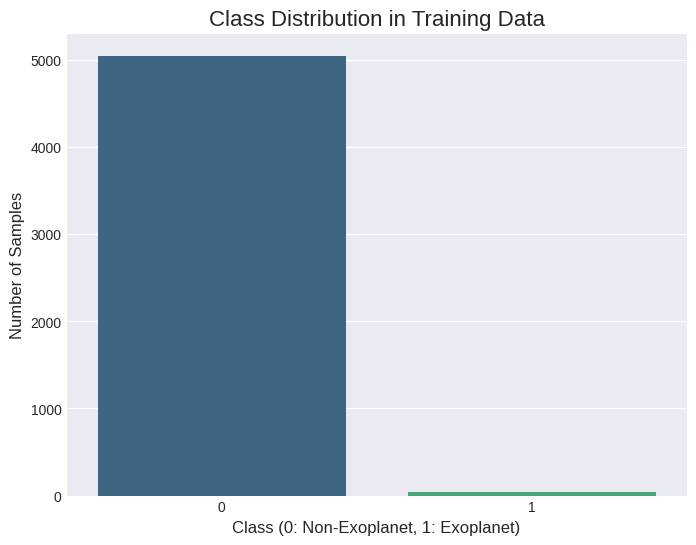

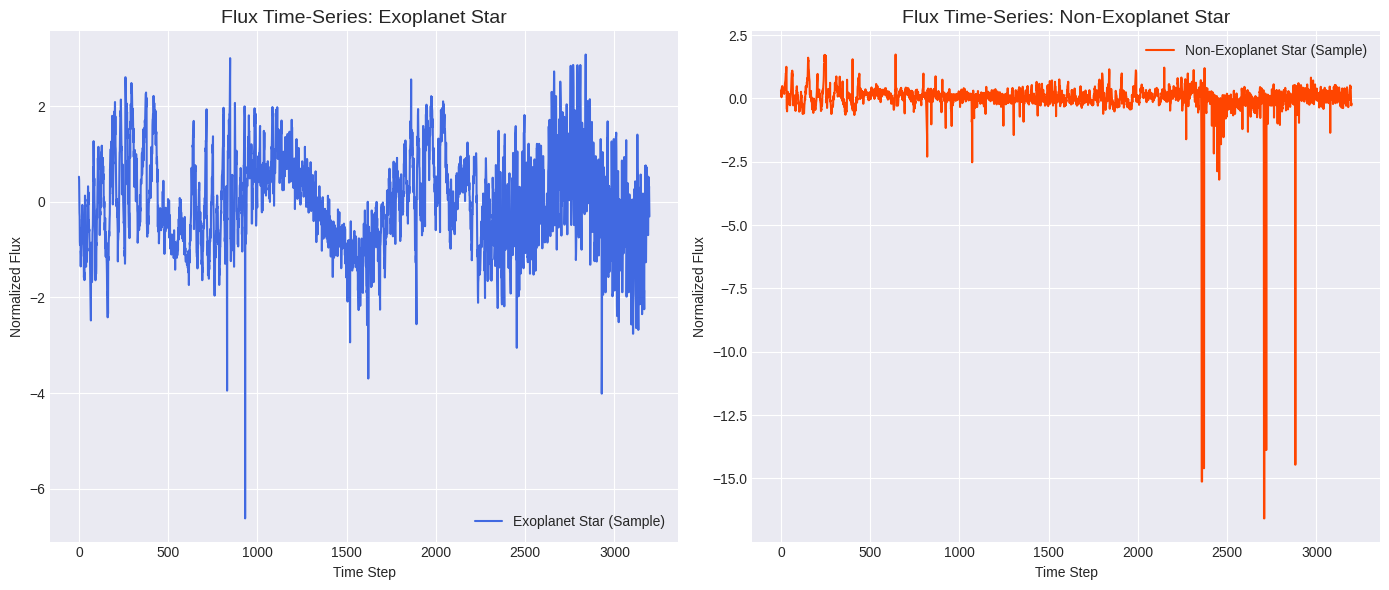

In [4]:
# --- Visualize Class Distribution ---
plt.figure(figsize=(8, 6))
class_counts = pd.Series(y_train).value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Class Distribution in Training Data', fontsize=16)
plt.xlabel('Class (0: Non-Exoplanet, 1: Exoplanet)', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
plt.xticks([0, 1])
print(f"Exoplanet Stars (Class 1): {class_counts[1]}")
print(f"Non-Exoplanet Stars (Class 0): {class_counts[0]}")
plt.show()

# --- Visualize Sample Flux Curves ---
plt.figure(figsize=(14, 6))

# Plot an exoplanet star (class 1)
plt.subplot(1, 2, 1)
plt.plot(X_train_norm[0, :], label='Exoplanet Star (Sample)', color='royalblue')
plt.title('Flux Time-Series: Exoplanet Star', fontsize=14)
plt.xlabel('Time Step')
plt.ylabel('Normalized Flux')
plt.legend()

# Plot a non-exoplanet star (class 0)
plt.subplot(1, 2, 2)
plt.plot(X_train_norm[100, :], label='Non-Exoplanet Star (Sample)', color='orangered')
plt.title('Flux Time-Series: Non-Exoplanet Star', fontsize=14)
plt.xlabel('Time Step')
plt.ylabel('Normalized Flux')
plt.legend()

plt.tight_layout()
plt.show()

# 3. Handling Class Imbalance

In [5]:

class_weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Keras expects a dictionary mapping class indices to their weights
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

print("Calculated Class Weights:")
print(f"Weight for Class 0 (Non-Exoplanet): {class_weights_dict[0]:.2f}")
print(f"Weight for Class 1 (Exoplanet): {class_weights_dict[1]:.2f}")

Calculated Class Weights:
Weight for Class 0 (Non-Exoplanet): 0.50
Weight for Class 1 (Exoplanet): 68.74


# 4.Ensemble Design

In [6]:
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, LSTM, Dropout, BatchNormalization, concatenate, Flatten

def build_ensemble_model(input_shape):
    """Builds the corrected CNN-LSTM ensemble model."""

    # --- Define Input Layer ---
    input_layer = Input(shape=input_shape, name='input_flux')

    # --- Branch 1: 1D-CNN for local patterns ---
    cnn_branch = Conv1D(filters=64, kernel_size=5, activation='relu', padding='same', name='cnn1')(input_layer)
    cnn_branch = BatchNormalization(name='cnn_bn1')(cnn_branch)
    cnn_branch = MaxPooling1D(pool_size=2, name='cnn_pool1')(cnn_branch)
    cnn_branch = Dropout(0.3, name='cnn_drop1')(cnn_branch)

    cnn_branch = Conv1D(filters=128, kernel_size=5, activation='relu', padding='same', name='cnn2')(cnn_branch)
    cnn_branch = BatchNormalization(name='cnn_bn2')(cnn_branch)
    cnn_branch = MaxPooling1D(pool_size=2, name='cnn_pool2')(cnn_branch)
    cnn_branch = Dropout(0.3, name='cnn_drop2')(cnn_branch)

    # --- THIS IS THE FIX ---
    # Flatten the 3D output of the CNN branch to a 2D vector
    cnn_flat = Flatten(name='cnn_flatten')(cnn_branch)

    # --- Branch 2: LSTM for long-term dependencies ---
    # The output of this layer is already a 2D vector
    lstm_branch = LSTM(64, return_sequences=False, name='lstm1')(input_layer)
    lstm_branch = Dropout(0.3, name='lstm_drop1')(lstm_branch)

    # --- Concatenate Branches (Stacking) ---
    # Now, we correctly concatenate two 2D tensors
    combined_features = concatenate([cnn_flat, lstm_branch], name='concatenate')

    # --- Meta-Learner Head ---
    # This dense layer learns from the combined features of both branches.
    meta_learner = Dense(64, activation='relu', name='meta_learner_dense')(combined_features)
    meta_learner = Dropout(0.5, name='meta_learner_drop')(meta_learner)

    # --- Output Layer ---
    # Sigmoid activation for binary classification.
    output_layer = Dense(1, activation='sigmoid', name='output_layer')(meta_learner)

    # --- Create and Compile Model ---
    model = Model(inputs=input_layer, outputs=output_layer)

    return model

# --- Example of how to build and view the model ---
# Get the input shape from our preprocessed data
input_shape = (X_train_reshaped.shape[1], 1)
model = build_ensemble_model(input_shape)

# Display the corrected model architecture
model.summary()

2025-10-05 12:27:46.708033: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_flux          │ (None, 3197, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn1 (Conv1D)       │ (None, 3197, 64)  │        384 │ input_flux[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_bn1             │ (None, 3197, 64)  │        256 │ cnn1[0][0]        │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_pool1           │ (None, 1598, 64)  │          0 │ cnn_bn1[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_drop1 (Dropout) │ (None, 1598, 64)  │          0 │ cnn_pool1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn2 (Conv1D)       │ (None, 1598, 128) │     41,088 │ cnn_drop1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_bn2             │ (None, 1598, 128) │        512 │ cnn2[0][0]        │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_pool2           │ (None, 799, 128)  │          0 │ cnn_bn2[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_drop2 (Dropout) │ (None, 799, 128)  │          0 │ cnn_pool2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm1 (LSTM)        │ (None, 64)        │     16,896 │ input_flux[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_flatten         │ (None, 102272)    │          0 │ cnn_drop2[0][0]   │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_drop1          │ (None, 64)        │          0 │ lstm1[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 102336)    │          0 │ cnn_flatten[0][0… │
│ (Concatenate)       │                   │            │ lstm_drop1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta_learner_dense  │ (None, 64)        │  6,549,568 │ concatenate[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta_learner_drop   │ (None, 64)        │          0 │ meta_learner_den… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 1)         │         65 │ meta_learner_dro… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,608,769 (25.21 MB)

 Trainable params: 6,608,385 (25.21 MB)

 Non-trainable params: 384 (1.50 KB)

# 5 Model training

In [7]:
#
# ---------------------------------
# --- 6. MODEL TRAINING -----------
# ---------------------------------
#

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0005),
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Setup EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss',
                               patience=10,
                               restore_best_weights=True,
                               verbose=1)

# Train the model
# We use a portion of the test set as a validation set for monitoring.
# For a final model, one might use k-fold cross-validation on the training set.
history = model.fit(X_train_reshaped,
                    y_train,
                    epochs=50,
                    batch_size=64,
                    validation_split=0.2, # Using part of training data for validation
                    class_weight=class_weights_dict,
                    callbacks=[early_stopping],
                    verbose=1)

Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.8884 - loss: 19.0362 - val_accuracy: 0.0000e+00 - val_loss: 14.8152
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 156s 2s/step - accuracy: 0.8690 - loss: 1.1607 - val_accuracy: 0.0059 - val_loss: 8.7039
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 154s 2s/step - accuracy: 0.9162 - loss: 0.2750 - val_accuracy: 0.0000e+00 - val_loss: 12.1405
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.8852 - loss: 1.1860 - val_accuracy: 0.0216 - val_loss: 9.3359
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9128 - loss: 0.1701 - val_accuracy: 0.2210 - val_loss: 6.0641
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9193 - loss: 0.2234 - val_accuracy: 0.3831 - val_loss: 5.1612
Epoch 7/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9426 - loss: 0.0829 - val_accuracy: 0.7279 - val_loss: 1.6590
Epoch 8/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 155s 2s/step - accuracy: 0.9407 - loss: 0.1784 - val_accuracy:

# 6. Evaluation and Results


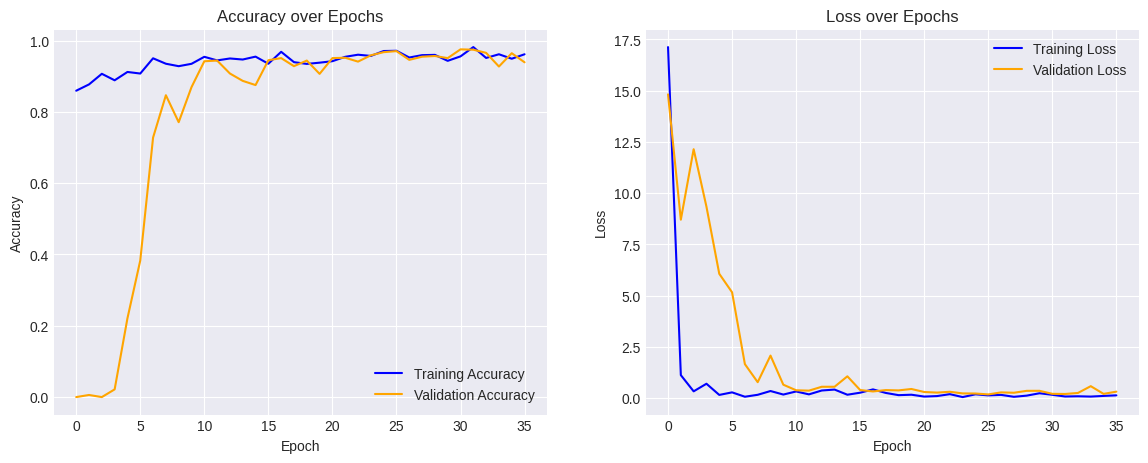

In [8]:


def plot_learning_curves(history):
    """Plots training & validation accuracy and loss."""
    plt.figure(figsize=(14, 5))

    # Plot accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_learning_curves(history)